In [1]:
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [2]:
DATA_DIR = r"F:\EDAIC-WOZ\data"
LABEL_DIR = r"F:\EDAIC-WOZ\labels"

print("Data directory:", DATA_DIR)
print("Label directory:", LABEL_DIR)

print("Data folder exists:", os.path.exists(DATA_DIR))
print("Label folder exists:", os.path.exists(LABEL_DIR))

Data directory: F:\EDAIC-WOZ\data
Label directory: F:\EDAIC-WOZ\labels
Data folder exists: True
Label folder exists: True


In [5]:
train_labels = pd.read_csv(
    os.path.join(LABEL_DIR, "train_split.csv")
)

print("Train shape:", train_labels.shape)

print("\nColumns:")
print(train_labels.columns.tolist())

print("\nFirst 5 rows:")
display(train_labels.head())

Train shape: (163, 6)

Columns:
['Participant_ID', 'Gender', 'PHQ_Binary', 'PHQ_Score', 'PCL-C (PTSD)', 'PTSD Severity']

First 5 rows:


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity
0,302,male,0,4,0,28
1,303,female,0,0,0,17
2,304,female,0,6,0,20
3,305,male,0,7,0,28
4,307,female,0,4,0,23


In [7]:
print("PHQ_Binary class distribution:")

print(
    train_labels["PHQ_Binary"]
    .value_counts()
    .sort_index()
)

print("\nClass percentages:")

print(
    train_labels["PHQ_Binary"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

PHQ_Binary class distribution:
PHQ_Binary
0    126
1     37
Name: count, dtype: int64

Class percentages:
PHQ_Binary
0    77.3
1    22.7
Name: proportion, dtype: float64


In [9]:
def extract_mfcc(pid):
    pid = int(pid)

    feature_path = os.path.join(
        DATA_DIR,
        f"{pid:03d}_P",
        "features",
        f"{pid:03d}_BoAW_openSMILE_2.3.0_MFCC.csv"
    )

    df = pd.read_csv(feature_path, header=None)

    # Remove metadata columns
    features = df.iloc[:, 2:]

    # Calculate statistics for each MFCC feature
    mean_features = features.mean(axis=0)
    std_features = features.std(axis=0)
    min_features = features.min(axis=0)
    max_features = features.max(axis=0)

    # Combine all statistics
    participant_features = np.concatenate([
        mean_features.values,
        std_features.values,
        min_features.values,
        max_features.values
    ])

    return participant_features

In [11]:
X_list = []
y_list = []
participant_ids = []

for _, row in train_labels.iterrows():
    pid = row["Participant_ID"]

    try:
        features = extract_mfcc(pid)

        X_list.append(features)
        y_list.append(row["PHQ_Binary"])
        participant_ids.append(pid)

    except Exception as e:
        print(f"Error for participant {pid}: {e}")

X = np.array(X_list)
y = np.array(y_list)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (163, 400)
y shape: (163,)


In [13]:
print("NaN values:", np.isnan(X).sum())
print("Inf values:", np.isinf(X).sum())
print("Number of participants:", X.shape[0])
print("Number of input features:", X.shape[1])

NaN values: 0
Inf values: 0
Number of participants: 163
Number of input features: 400


In [15]:
model = Pipeline([
    ("selector", SelectKBest(score_func=f_classif, k=10)),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

In [17]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

f1_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print("Fold F1 scores:", f1_scores)
print(f"Mean F1: {f1_scores.mean():.4f}")
print(f"Std F1:  {f1_scores.std():.4f}")
print(f"F1 Score: {f1_scores.mean():.4f} ± {f1_scores.std():.4f}")

Fold F1 scores: [0.28571429 0.28571429 0.4        0.38095238 0.42105263]
Mean F1: 0.3547
Std F1:  0.0577
F1 Score: 0.3547 ± 0.0577


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 208 209 210 211 212 213 214 215 216 217 219
 220 222 223 224 225 226 228 229 230 231 232 233 235 237 239 240 241 242
 243 244 245 246 247 248 249 250 252 253 254 255 256 257 258 259 260 262
 263 264 265 267 269 270 271 272 273 274 275 276 277 278 279 280 281 282
 283 284 285 286 287 289 290 291 292 293 294 295 296 297 298 299] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:113: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 208 209 210 211 212 213 214 215 216 217 219
 220 222 223 224 225 226 228 229 230 231 232 233 235 237 239 240 241 242


In [21]:
oof_predictions = cross_val_predict(
    model,
    X,
    y,
    cv=cv
)

print(
    "Out-of-fold predictions shape:",
    oof_predictions.shape
)

Out-of-fold predictions shape: (163,)


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 208 209 210 211 212 213 214 215 216 217 219
 220 222 223 224 225 226 228 229 230 231 232 233 235 237 239 240 241 242
 243 244 245 246 247 248 249 250 252 253 254 255 256 257 258 259 260 262
 263 264 265 267 269 270 271 272 273 274 275 276 277 278 279 280 281 282
 283 284 285 286 287 289 290 291 292 293 294 295 296 297 298 299] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:113: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 208 209 210 211 212 213 214 215 216 217 219
 220 222 223 224 225 226 228 229 230 231 232 233 235 237 239 240 241 242


In [23]:
print("Classification Report:")

print(
    classification_report(
        y,
        oof_predictions,
        target_names=[
            "Non-Depressed",
            "Depressed"
        ]
    )
)

Classification Report:
               precision    recall  f1-score   support

Non-Depressed       0.81      0.64      0.72       126
    Depressed       0.29      0.49      0.36        37

     accuracy                           0.61       163
    macro avg       0.55      0.56      0.54       163
 weighted avg       0.69      0.61      0.64       163



Confusion Matrix:
[[81 45]
 [19 18]]


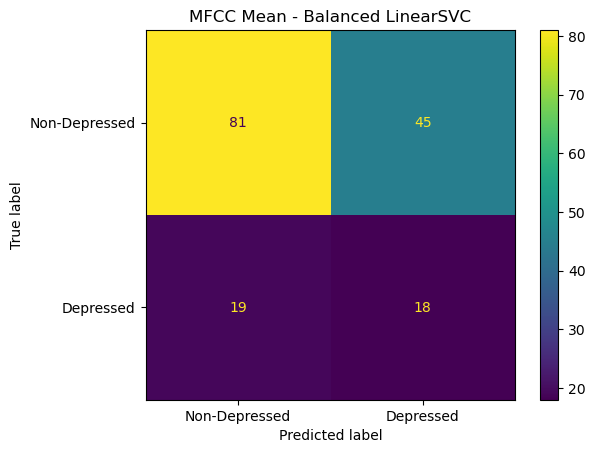

In [25]:
cm = confusion_matrix(
    y,
    oof_predictions
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-Depressed",
        "Depressed"
    ]
)

disp.plot()

plt.title("MFCC Mean - Balanced LinearSVC")
plt.show()

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=cv,
    method="predict"
)

mean_f1 = f1_scores.mean()
std_f1 = f1_scores.std()

accuracy = accuracy_score(y, y_pred)
dep_precision = precision_score(y, y_pred, pos_label=1)
dep_recall = recall_score(y, y_pred, pos_label=1)
dep_f1 = f1_score(y, y_pred, pos_label=1)

results = pd.DataFrame([{
    "Model": "LinearSVC + Balanced Class Weight",
    "Features": "MFCC Mean + Std + Min + Max",
    "Input Features": X.shape[1],
    "Selected Features": 10,
    "CV Folds": 5,
    "Mean F1": mean_f1,
    "Std F1": std_f1,
    "Accuracy": accuracy,
    "Depressed Precision": dep_precision,
    "Depressed Recall": dep_recall,
    "Depressed F1": dep_f1
}])

results

C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 208 209 210 211 212 213 214 215 216 217 219
 220 222 223 224 225 226 228 229 230 231 232 233 235 237 239 240 241 242
 243 244 245 246 247 248 249 250 252 253 254 255 256 257 258 259 260 262
 263 264 265 267 269 270 271 272 273 274 275 276 277 278 279 280 281 282
 283 284 285 286 287 289 290 291 292 293 294 295 296 297 298 299] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:113: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 208 209 210 211 212 213 214 215 216 217 219
 220 222 223 224 225 226 228 229 230 231 232 233 235 237 239 240 241 242


,Model,Features,Input Features,Selected Features,CV Folds,Mean F1,Std F1,Accuracy,Depressed Precision,Depressed Recall,Depressed F1
0,LinearSVC + Balanced Class Weight,MFCC Mean + Std + Min + Max,400,10,5,0.354687,0.057727,0.607362,0.285714,0.486486,0.36
